# Phase 4 — Exploratory Data Analysis & Data Quality Investigation
**Used Car Price Prediction in Vietnam: An End-to-End Machine Learning Project**

- **Tác giả**: Senior Data Scientist & ML Engineer pair-programming cùng Sinh viên AI
- **Dataset**: `data/raw/external/mquaan_car_price/car_detail.csv` (Primary), `car_sell_processed.csv` (Companion)
- **Môi trường**: Python 3.11, pandas, numpy, matplotlib, seaborn, scipy
- **Mục tiêu**:
  1. Xác minh tính toàn vẹn và mã băm SHA-256 của tập dữ liệu thị trường thực tế.
  2. Rà soát Data Dictionary và bảng đối chiếu Schema Mapping 14 trường.
  3. Đo lường Data Quality Profile (Missing values, Duplicates, Price parsing, Numeric validity).
  4. Trực quan hóa toàn diện biến mục tiêu `price_vnd`, các đặc trưng `year`, `mileage_km`, `brand`, `body_type`, `transmission`, `origin`.
  5. Phân tích địa bàn (Geo-source) và các rủi ro thiên lệch chọn mẫu (Selection Bias).
  6. Khảo sát tương quan định lượng (Correlation Heatmap) và diễn giải đúng bản chất toán học.
  7. Tái thẩm định hợp đồng kiểm định (`src/data/validation.py`) và đề xuất chính sách làm sạch dữ liệu (Data Cleaning Policy) cho Phase 5.


## 1. Thiết lập Môi trường & Xác minh Tính Toàn vẹn Dữ liệu

In [1]:
import sys
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn tương đối linh hoạt
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ai-club-end-training" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_dataset import compute_sha256
from src.data.price_parser import parse_vietnamese_price_to_vnd

# Cấu hình thẩm mỹ trực quan
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", palette="deep")

print("Project root:", PROJECT_ROOT)


Project root: D:\ai-club-end-training


### 1.1. Kiểm tra Checksum SHA-256 đối chiếu Metadata

In [2]:
detail_path = PROJECT_ROOT / "data" / "raw" / "external" / "mquaan_car_price" / "car_detail.csv"
proc_path = PROJECT_ROOT / "data" / "raw" / "external" / "mquaan_car_price" / "car_sell_processed.csv"
meta_path = PROJECT_ROOT / "data" / "metadata" / "ingestion_mquaan_car_price.json"

sha_detail = compute_sha256(detail_path)
sha_proc = compute_sha256(proc_path)

sidecar_detail = Path(str(detail_path) + ".sha256").read_text(encoding="utf-8").strip().split()[0]
sidecar_proc = Path(str(proc_path) + ".sha256").read_text(encoding="utf-8").strip().split()[0]

with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

meta_shas = {item["filename"]: item["sha256"] for item in meta["ingestion_metadata"]["staged_files"] if "sha256" in item}

print(f"car_detail.csv SHA-256:       {sha_detail}")
print(f"  -> Match Sidecar:           {sha_detail == sidecar_detail}")
print(f"  -> Match Ingestion Metadata: {sha_detail == meta_shas.get('car_detail.csv')}")

print(f"\ncar_sell_processed.csv SHA-256: {sha_proc}")
print(f"  -> Match Sidecar:           {sha_proc == sidecar_proc}")
print(f"  -> Match Ingestion Metadata: {sha_proc == meta_shas.get('car_sell_processed.csv')}")

assert sha_detail == sidecar_detail == meta_shas.get('car_detail.csv'), "Lỗi: Checksum car_detail.csv không khớp!"
assert sha_proc == sidecar_proc == meta_shas.get('car_sell_processed.csv'), "Lỗi: Checksum car_sell_processed.csv không khớp!"
print("\n=> TOÀN BỘ DỮ LIỆU ĐẠT CHUẨN TOÀN VẸN 100%!")


car_detail.csv SHA-256:       44c13afc5982f7abc51611fc56eeefd02df8e47f3224112f51b76514a7328f08
  -> Match Sidecar:           True
  -> Match Ingestion Metadata: True

car_sell_processed.csv SHA-256: 1d0c0d2f5a920f19eee09cffc84f30c7bc7496ac5bcb35260ccfbbd93c89437c
  -> Match Sidecar:           True
  -> Match Ingestion Metadata: True

=> TOÀN BỘ DỮ LIỆU ĐẠT CHUẨN TOÀN VẸN 100%!


### 1.2. Nạp Dữ liệu Thô và Khảo sát Cấu trúc Bảng

In [3]:
df_raw = pd.read_csv(detail_path)
df_proc = pd.read_csv(proc_path)

print(f"Bảng chính car_detail.csv:        {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
print(f"Bảng phụ car_sell_processed.csv: {df_proc.shape[0]:,} dòng x {df_proc.shape[1]} cột")
print("\nCác cột trong car_detail.csv:")
print(list(df_raw.columns))
print("\nCác cột trong car_sell_processed.csv:")
print(list(df_proc.columns))


Bảng chính car_detail.csv:        30,652 dòng x 21 cột
Bảng phụ car_sell_processed.csv: 30,652 dòng x 21 cột

Các cột trong car_detail.csv:
['Mã tin', 'Xuất xứ', 'Tình trạng', 'Dòng xe', 'Số Km đã đi', 'Màu ngoại thất', 'Màu nội thất', 'Số cửa', 'Số chỗ ngồi', 'Động cơ', 'Hệ thống nạp nhiên liệu', 'Hộp số', 'Dẫn động', 'Tiêu thụ nhiên liệu', 'Mô tả', 'Hãng', 'Grade', 'Năm sản xuất', 'Tên xe', 'Giá', 'URL']

Các cột trong car_sell_processed.csv:
['Xuất xứ', 'Tình trạng', 'Dòng xe', 'Số Km đã đi', 'Màu ngoại thất', 'Màu nội thất', 'Số cửa', 'Số chỗ ngồi', 'Hệ thống nạp nhiên liệu', 'Hộp số', 'Dẫn động', 'Tiêu thụ (L/100Km)', 'Hãng', 'Bản', 'Năm sản xuất', 'Tên xe', 'Giá', 'Tỉnh', 'Nhiên liệu', 'Dung tích xi lanh (L)', 'Bán bởi']


### 1.3. Khảo sát Mối liên hệ giữa Hai Bảng Dữ liệu
> [!NOTE]
> Bảng `car_sell_processed.csv` đã bị lược bỏ cột định danh `Mã tin`, URL và mô tả bài đăng; đồng thời tách trường động cơ và điền sẵn mã tỉnh thành.
> Tuân thủ nguyên tắc liêm chính dữ liệu: Ta **không giả định** hai bảng có thể nối mù theo thứ tự dòng hay index. Ta sử dụng `car_detail.csv` làm **bảng phân tích chính**, và chỉ tham chiếu phân phối tỉnh thành từ `car_sell_processed.csv` ở phần phân tích địa phương.


In [4]:
df_raw[['Mã tin', 'Hãng', 'Grade', 'Năm sản xuất', 'Số Km đã đi', 'Giá']].head()


,Mã tin,Hãng,Grade,Năm sản xuất,Số Km đã đi,Giá
0,17042,Suzuki,Super Carry Truck,2022.0,0 Km,249 Triệu
1,53794,Toyota,Land Cruiser,2022.0,0 Km,4 Tỷ 286 Triệu
2,73954,Toyota,Innova,2023.0,0 Km,885 Triệu
3,74150,Toyota,Corolla Cross,2023.0,0 Km,754 Triệu
4,87573,Toyota,Innova,2022.0,0 Km,850 Triệu


## 2. Đối chiếu Từ điển Dữ liệu (Data Dictionary Review) & Schema Mapping
Bảng đối chiếu 14 trường chuẩn dự án với các trường thô trong `car_detail.csv`:

| Trường chuẩn (`target_field`) | Cột gốc (`car_detail.csv`) | Kiểu dữ liệu gốc | Ý nghĩa nghiệp vụ | Tỷ lệ khuyết | Phân loại ánh xạ |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`price_vnd`** | `Giá` | `object` (str) | Giá niêm yết (VND) | 0.00% | **Needs Unit Conversion** (Qua `price_parser.py`) |
| **`brand`** | `Hãng` | `object` (str) | Thương hiệu xe | 0.00% | **Needs Normalization** (Trim, sửa 'Mercedes Benz') |
| **`model`** | `Grade` | `object` (str) | Dòng/mẫu xe | 0.00% | **Needs Normalization** (Chuẩn hóa ký tự) |
| **`year`** | `Năm sản xuất` | `float64` / `int` | Năm sản xuất | 0.10% | **Directly Mapped** (Ép kiểu int) |
| **`mileage_km`** | `Số Km đã đi` | `object` (str) | Số kilomet đã đi | 0.00% | **Needs Unit Conversion** (Bỏ ' Km', ',') |
| **`fuel_type`** | `Động cơ` | `object` (str) | Loại nhiên liệu | 0.00% | **Needs Normalization** (Trích xuất Xăng/Dầu/Điện) |
| **`transmission`** | `Hộp số` | `object` (str) | Hộp số | 0.00% | **Needs Normalization** (Tự động vs Sàn) |
| **`origin`** | `Xuất xứ` | `object` (str) | Xuất xứ xe | 0.00% | **Directly Mapped** (Trong nước / Nhập khẩu) |
| **`body_type`** | `Dòng xe` | `object` (str) | Kiểu dáng xe | 0.00% | **Directly Mapped** (Sedan, SUV, Crossover...) |
| **`seats`** | `Số chỗ ngồi` | `object` (str) | Số chỗ ngồi | 0.00% | **Needs Unit Conversion** (Bóc tách số) |
| **`listing_id`** | `Mã tin` | `int64` | Khóa định danh tin | 0.00% | **Directly Mapped** (Khóa phân biệt deduplication) |
| **`location_province`** | *(Có ở df_proc)* | `object` (str) | Tỉnh/thành rao bán | - | **Unverified in primary table** (Tham chiếu bảng phụ) |
| **`source_url`** | `URL` | `object` (str) | Link bài đăng gốc | 0.00% | **Directly Mapped** (Kiểm chứng thực tế) |
| **`crawl_date`** | *(Không có)* | - | Ngày cào dữ liệu | 100% | **UNAVAILABLE** (Mặc định mốc 2023-2024 theo repo) |


## 3. Tiền Xử Lý Dữ Liệu Cho Phân Tích (Non-Destructive)

In [5]:
df = df_raw.copy()

# 1. Parse Giá
df['price_vnd'] = [parse_vietnamese_price_to_vnd(p) for p in df['Giá']]
df['price_billion'] = df['price_vnd'] / 1_000_000_000
df['log_price'] = np.log(df['price_vnd'])

# 2. Parse Năm & Tuổi xe
df['year'] = pd.to_numeric(df['Năm sản xuất'], errors='coerce')
df['car_age'] = 2024 - df['year']

# 3. Parse Mileage
def clean_km(val):
    if pd.isna(val):
        return np.nan
    s = str(val).replace(' Km', '').replace(',', '').strip()
    try:
        return float(s)
    except:
        return np.nan

df['mileage_km'] = df['Số Km đã đi'].apply(clean_km)

# 4. Parse Seats & Doors
df['seats'] = df['Số chỗ ngồi'].astype(str).str.extract(r'(\d+)').astype(float)
df['doors'] = df['Số cửa'].astype(str).str.extract(r'(\d+)').astype(float)

# 5. Categorical
df['brand'] = df['Hãng'].astype(str).str.strip().replace({'Mercedes Benz': 'Mercedes-Benz'})
df['model'] = df['Grade'].astype(str).str.strip()
df['body_type'] = df['Dòng xe'].astype(str).str.strip()
df['origin'] = df['Xuất xứ'].astype(str).str.strip()
df['condition'] = df['Tình trạng'].astype(str).str.strip()
df['transmission'] = df['Hộp số'].astype(str).str.strip()

# 6. Fuel Type & Displacement
def extract_fuel(s):
    s_low = str(s).lower()
    if 'xăng' in s_low: return 'Xăng'
    if 'dầu' in s_low or 'diesel' in s_low: return 'Dầu'
    if 'điện' in s_low or 'electric' in s_low: return 'Điện'
    if 'hybrid' in s_low: return 'Hybrid'
    return 'Khác'

def extract_displacement(val):
    if pd.isna(val): return np.nan
    for part in str(val).split('\t'):
        part_clean = part.replace('L', '').strip()
        try:
            return float(part_clean)
        except:
            pass
    return np.nan

df['fuel_type'] = df['Động cơ'].apply(extract_fuel)
df['engine_displacement_l'] = df['Động cơ'].apply(extract_displacement)

print("Tập dữ liệu đã chuẩn hóa trường (df):", df.shape)
df[['price_vnd', 'year', 'mileage_km', 'brand', 'fuel_type', 'transmission', 'engine_displacement_l']].head()


Tập dữ liệu đã chuẩn hóa trường (df): (30652, 37)


,price_vnd,year,mileage_km,brand,fuel_type,transmission,engine_displacement_l
0,249000000,2022.0,0.0,Suzuki,Xăng,Số tay,1.0
1,4286000000,2022.0,0.0,Toyota,Xăng,Số tự động,3.4
2,885000000,2023.0,0.0,Toyota,Xăng,Số tự động,2.0
3,754000000,2023.0,0.0,Toyota,Xăng,Số tự động,1.8
4,850000000,2022.0,0.0,Toyota,Xăng,Số tự động,2.0


## 4. Đo Lường Chất Lượng Dữ Liệu (Data Quality Profiling)

In [6]:
# 4.1. Missing values
missing_df = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Rate (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
}).sort_values(by='Missing Count', ascending=False)

print("=== THỐNG KÊ KHUYẾT THIẾU TRÊN 21 CỘT GỐC ===")
display(missing_df[missing_df['Missing Count'] > 0])

# 4.2. Deduplication
print("\n=== KIỂM TRA TRÙNG LẶP ===")
print("Số mã tin (Mã tin) duy nhất:   ", df_raw['Mã tin'].nunique(), f"/ {len(df_raw)}")
print("Số bản ghi trùng lặp mã tin:    ", df_raw.duplicated(subset=['Mã tin']).sum())
print("Số bản ghi trùng lặp toàn bộ:   ", df_raw.duplicated().sum())

# 4.3. Price normalization audit
parsed_valid = df['price_vnd'].notna().sum()
print("\n=== KIỂM TOÁN PARSE GIÁ ===")
print(f"Tổng số tin đánh giá:           {len(df):,}")
print(f"Số giá parse thành công:        {parsed_valid:,} ({(parsed_valid/len(df))*100:.2f}%)")
print(f"Số giá parse thất bại:          {len(df) - parsed_valid}")
print(f"Giá < 30 triệu VND:             {(df['price_vnd'] < 30_000_000).sum()}")
print(f"Giá > 50 tỷ VND:                {(df['price_vnd'] > 50_000_000_000).sum()}")


=== THỐNG KÊ KHUYẾT THIẾU TRÊN 21 CỘT GỐC ===


,Missing Count,Missing Rate (%)
Hệ thống nạp nhiên liệu,23907,77.994911
Năm sản xuất,32,0.104398



=== KIỂM TRA TRÙNG LẶP ===
Số mã tin (Mã tin) duy nhất:    30652 / 30652
Số bản ghi trùng lặp mã tin:     0
Số bản ghi trùng lặp toàn bộ:    0

=== KIỂM TOÁN PARSE GIÁ ===
Tổng số tin đánh giá:           30,652
Số giá parse thành công:        30,652 (100.00%)
Số giá parse thất bại:          0
Giá < 30 triệu VND:             13
Giá > 50 tỷ VND:                1


## 5. Phân Tích Biến Mục Tiêu `price_vnd` (Target Distribution)
Ta khảo sát phân phối của giá rao bán ô tô trên thị trường thực tế:
- Kiểm tra tính lệch phải (Right-skewness) do sự xuất hiện của các dòng xe hạng sang và siêu xe.
- Đánh giá hiệu quả của phép biến đổi logarit $\ln(y)$ để đưa biến mục tiêu về dạng gần phân phối chuẩn.


=== THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU PRICE_VND ===
  count   :           30,652 VND (   0.000 Tỷ)
  mean    :    1,180,744,682 VND (   1.181 Tỷ)
  std     :    2,068,362,485 VND (   2.068 Tỷ)
  min     :       18,000,000 VND (   0.018 Tỷ)
  25%     :      410,000,000 VND (   0.410 Tỷ)
  50%     :      620,000,000 VND (   0.620 Tỷ)
  75%     :    1,030,000,000 VND (   1.030 Tỷ)
  max     :   54,000,000,000 VND (  54.000 Tỷ)


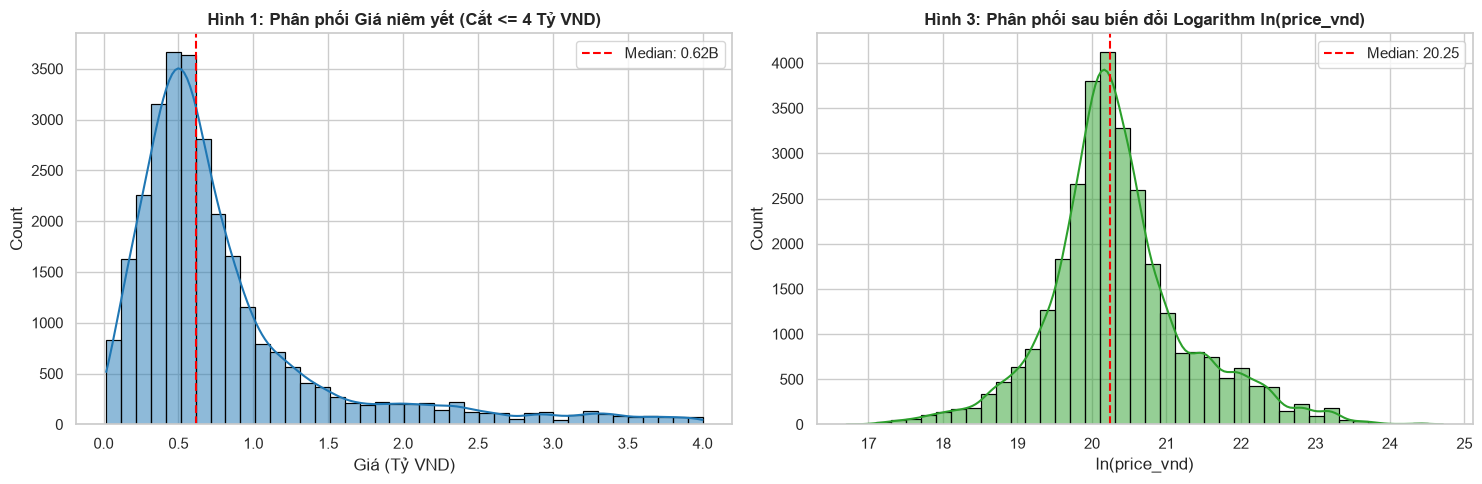

In [7]:
stats = df['price_vnd'].describe()
print("=== THỐNG KÊ MÔ TẢ BIẾN MỤC TIÊU PRICE_VND ===")
for k, v in stats.items():
    print(f"  {k:8s}: {v:16,.0f} VND ({v/1e9:8.3f} Tỷ)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Hist raw price <= 4 tỷ
sub_p = df[df['price_billion'] <= 4]['price_billion']
sns.histplot(sub_p, bins=40, kde=True, ax=ax1, color='#1f77b4', edgecolor='black')
ax1.set_title("Hình 1: Phân phối Giá niêm yết (Cắt <= 4 Tỷ VND)", fontweight='bold')
ax1.set_xlabel("Giá (Tỷ VND)")
ax1.axvline(df['price_billion'].median(), color='red', linestyle='--', label=f"Median: {df['price_billion'].median():.2f}B")
ax1.legend()

# Hist log_price
sns.histplot(df['log_price'], bins=40, kde=True, ax=ax2, color='#2ca02c', edgecolor='black')
ax2.set_title("Hình 3: Phân phối sau biến đổi Logarithm ln(price_vnd)", fontweight='bold')
ax2.set_xlabel("ln(price_vnd)")
ax2.axvline(df['log_price'].median(), color='red', linestyle='--', label=f"Median: {df['log_price'].median():.2f}")
ax2.legend()

plt.tight_layout()
plt.show()


## 6. Mối Quan Hệ Giữa Giá và Năm Sản Xuất (Price vs Year)

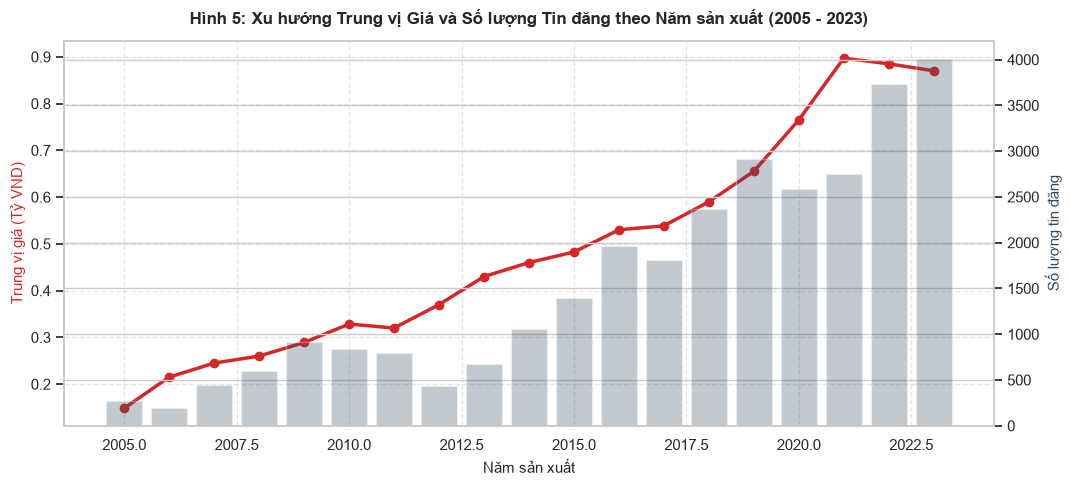

In [8]:
year_stats = df.groupby('year')['price_billion'].agg(['median', 'count']).loc[2005:2023]

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.plot(year_stats.index, year_stats['median'], color='#d62728', marker='o', linewidth=2.5, label='Trung vị giá (Tỷ VND)')
ax2.bar(year_stats.index, year_stats['count'], color='#34495e', alpha=0.3, label='Số lượng tin đăng')

ax1.set_xlabel("Năm sản xuất", fontsize=11)
ax1.set_ylabel("Trung vị giá (Tỷ VND)", color='#d62728', fontsize=11)
ax2.set_ylabel("Số lượng tin đăng", color='#34495e', fontsize=11)
plt.title("Hình 5: Xu hướng Trung vị Giá và Số lượng Tin đăng theo Năm sản xuất (2005 - 2023)", fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 7. Phân Tích Thương Hiệu (Brand Analysis)

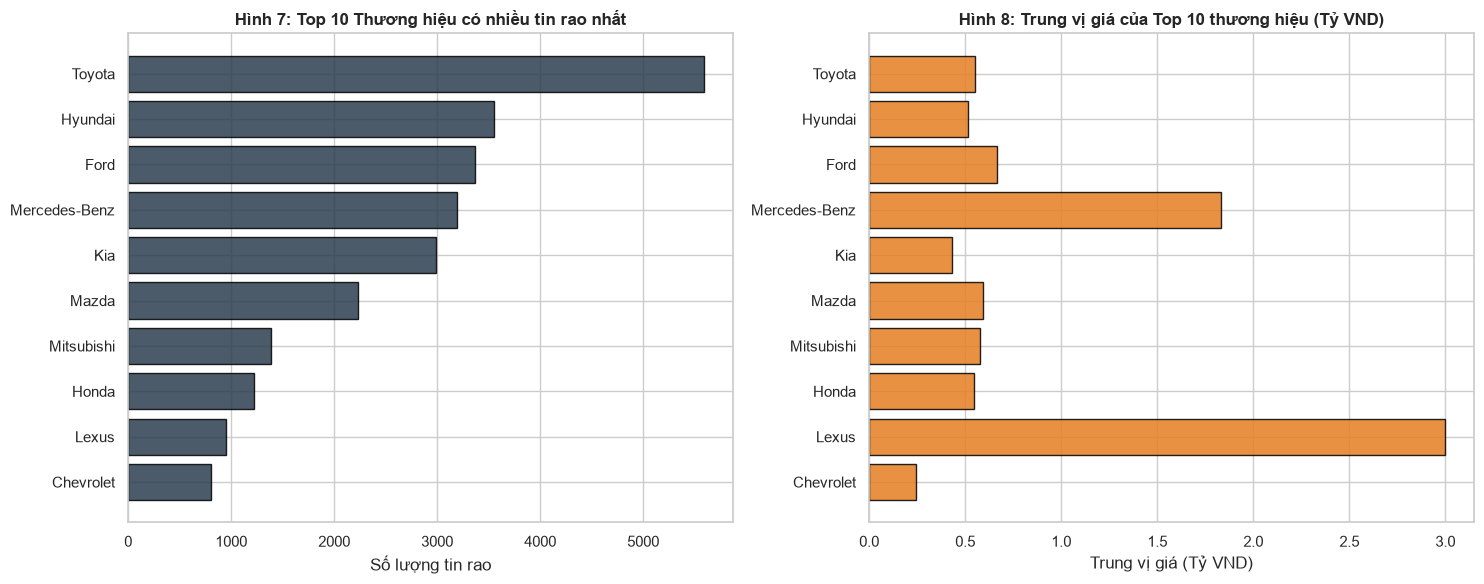

In [9]:
top_brands = df['brand'].value_counts().head(10)
brand_medians = df[df['brand'].isin(top_brands.index)].groupby('brand')['price_billion'].agg(['median', 'count']).loc[top_brands.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Top brand counts
ax1.barh(np.arange(len(top_brands)), top_brands.values, color='#2c3e50', edgecolor='black', alpha=0.85)
ax1.set_yticks(np.arange(len(top_brands)))
ax1.set_yticklabels(top_brands.index)
ax1.invert_yaxis()
ax1.set_title("Hình 7: Top 10 Thương hiệu có nhiều tin rao nhất", fontweight='bold')
ax1.set_xlabel("Số lượng tin rao")

# Top brand median prices
ax2.barh(np.arange(len(brand_medians)), brand_medians['median'], color='#e67e22', edgecolor='black', alpha=0.85)
ax2.set_yticks(np.arange(len(brand_medians)))
ax2.set_yticklabels(brand_medians.index)
ax2.invert_yaxis()
ax2.set_title("Hình 8: Trung vị giá của Top 10 thương hiệu (Tỷ VND)", fontweight='bold')
ax2.set_xlabel("Trung vị giá (Tỷ VND)")

plt.tight_layout()
plt.show()


## 8. Phân Tích Số Kilomet Đã Đi (Mileage Analysis)
Điều tra phân phối ODO, hiện tượng ODO = 0 km và các giá trị ngoại lai lớn.


Số lượng tin có ODO = 0 km: 10,442 (34.1%)
Số lượng tin có ODO > 1,000,000 km: 124


C:\Users\DELL\AppData\Local\Temp\ipykernel_36420\867096887.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


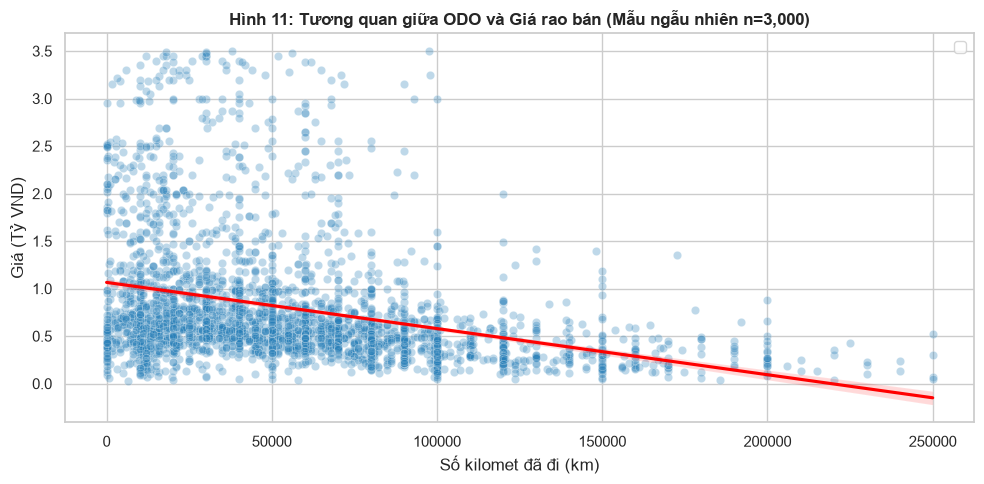

In [10]:
zero_km = (df['mileage_km'] == 0).sum()
print(f"Số lượng tin có ODO = 0 km: {zero_km:,} ({(zero_km/len(df))*100:.1f}%)")
print(f"Số lượng tin có ODO > 1,000,000 km: {(df['mileage_km'] > 1_000_000).sum()}")

# Scatter plot sampling 3000 points
sample_scatter = df[(df['mileage_km'] > 0) & (df['mileage_km'] <= 250_000) & (df['price_billion'] <= 3.5)].sample(3000, random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample_scatter, x='mileage_km', y='price_billion', alpha=0.3, color='#2980b9')
sns.regplot(data=sample_scatter, x='mileage_km', y='price_billion', scatter=False, color='red', line_kws={'label': 'Đường hồi quy OLS'})
plt.title("Hình 11: Tương quan giữa ODO và Giá rao bán (Mẫu ngẫu nhiên n=3,000)", fontweight='bold')
plt.xlabel("Số kilomet đã đi (km)")
plt.ylabel("Giá (Tỷ VND)")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Phân Tích Các Đặc Trưng Phân Loại (Categorical Features)

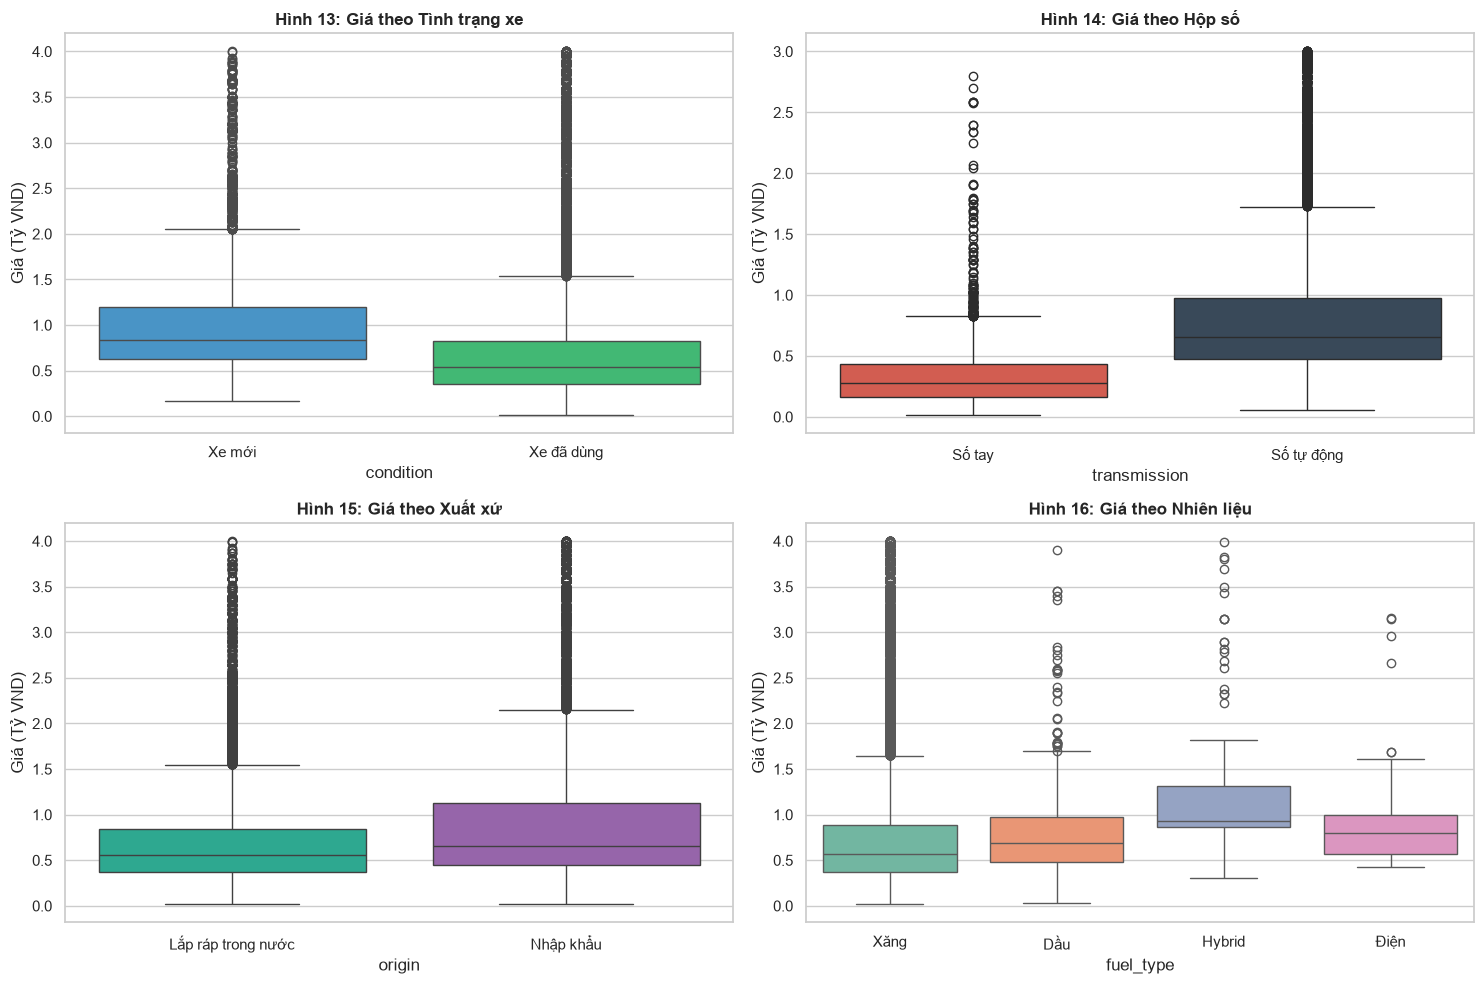

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Condition
sns.boxplot(data=df[df['price_billion'] <= 4], x='condition', y='price_billion', hue='condition', ax=axes[0, 0], palette=['#3498db', '#2ecc71'], legend=False)
axes[0, 0].set_title("Hình 13: Giá theo Tình trạng xe", fontweight='bold')
axes[0, 0].set_ylabel("Giá (Tỷ VND)")

# 2. Transmission
sns.boxplot(data=df[df['transmission'].isin(['Số tự động', 'Số tay']) & (df['price_billion'] <= 3)], x='transmission', y='price_billion', hue='transmission', ax=axes[0, 1], palette=['#e74c3c', '#34495e'], legend=False)
axes[0, 1].set_title("Hình 14: Giá theo Hộp số", fontweight='bold')
axes[0, 1].set_ylabel("Giá (Tỷ VND)")

# 3. Origin
sns.boxplot(data=df[df['origin'].isin(['Lắp ráp trong nước', 'Nhập khẩu']) & (df['price_billion'] <= 4)], x='origin', y='price_billion', hue='origin', ax=axes[1, 0], palette=['#1abc9c', '#9b59b6'], legend=False)
axes[1, 0].set_title("Hình 15: Giá theo Xuất xứ", fontweight='bold')
axes[1, 0].set_ylabel("Giá (Tỷ VND)")

# 4. Fuel type
top_fuels = ['Xăng', 'Dầu', 'Điện', 'Hybrid']
sns.boxplot(data=df[df['fuel_type'].isin(top_fuels) & (df['price_billion'] <= 4)], x='fuel_type', y='price_billion', hue='fuel_type', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title("Hình 16: Giá theo Nhiên liệu", fontweight='bold')
axes[1, 1].set_ylabel("Giá (Tỷ VND)")

plt.tight_layout()
plt.show()


## 10. Ma Trận Tương Quan Tuyến Tính (Correlation Heatmap)
> [!IMPORTANT]
> **Lưu ý phương pháp luận**:
> - Hệ số tương quan Pearson ($r$) chỉ phản ánh mức độ quan hệ tuyến tính giữa hai biến định lượng, **tuyệt đối không đồng nghĩa với quan hệ nhân quả (Correlation $\ne$ Causation)**.
> - Các biến khuyết thiếu được xử lý theo cơ chế pairwise-deletion khi tính ma trận hiệp phương sai.


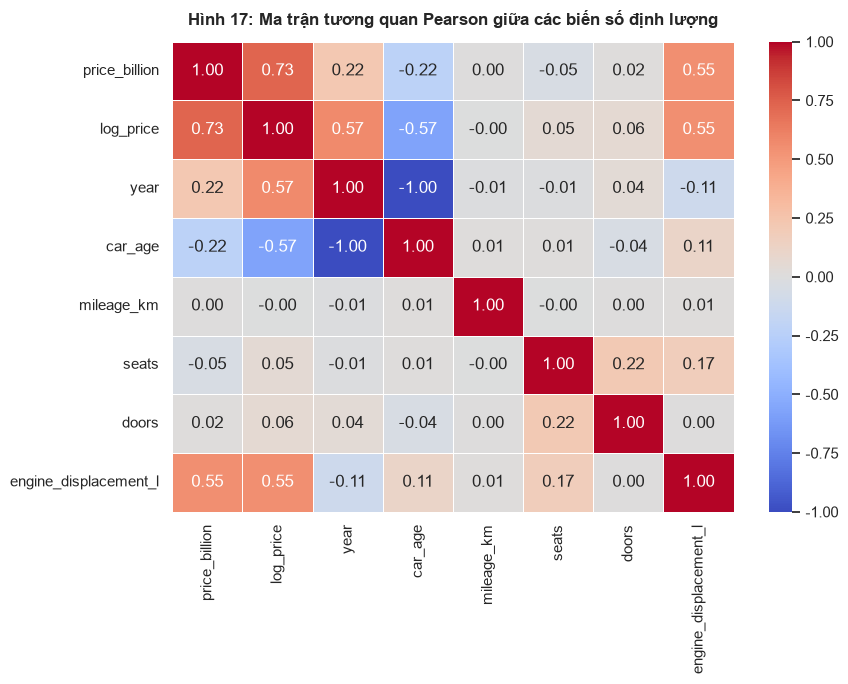

In [12]:
num_cols = ['price_billion', 'log_price', 'year', 'car_age', 'mileage_km', 'seats', 'doors', 'engine_displacement_l']
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Hình 17: Ma trận tương quan Pearson giữa các biến số định lượng", fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 11. Phân Tích Địa Bàn & Thiên Lệch Chọn Mẫu (Geo-source & Selection Bias)

In [13]:
top_prov = df_proc['Tỉnh'].value_counts().head(10)
print("=== TOP 10 TỈNH THÀNH CÓ LƯỢNG TIN RAO LỚN NHẤT ===")
for p, count in top_prov.items():
    print(f"  {p:20s}: {count:6,} tin ({(count/len(df_proc))*100:5.1f}%)")

hn_hcm_share = ((top_prov['Hanoi'] + top_prov['Ho Chi Minh City']) / len(df_proc)) * 100
print(f"\nTổng tỷ trọng Hà Nội + TP.HCM: {hn_hcm_share:.1f}%")


=== TOP 10 TỈNH THÀNH CÓ LƯỢNG TIN RAO LỚN NHẤT ===
  Hanoi               : 14,612 tin ( 47.7%)
  Ho Chi Minh City    :  5,681 tin ( 18.5%)
  Hai Phong           :    960 tin (  3.1%)
  Binh Duong          :    865 tin (  2.8%)
  Dong Nai            :    627 tin (  2.0%)
  Dak Lak             :    560 tin (  1.8%)
  Da Nang             :    435 tin (  1.4%)
  Binh Phuoc          :    407 tin (  1.3%)
  Ba Ria - Vung Tau   :    390 tin (  1.3%)
  Binh Thuan          :    386 tin (  1.3%)

Tổng tỷ trọng Hà Nội + TP.HCM: 66.2%


## 12. Tổng Hợp & Đề Xuất Chính Sách Làm Sạch Dữ Liệu (Cleaning Policy)

Dựa trên kết quả khám phá dữ liệu thực nghiệm, nhóm đề xuất chính sách làm sạch dữ liệu cho Phase 5:
1. **Phân biệt rạch ròi 3 khái niệm**:
   - **Tính hợp lệ của dữ liệu (Data Validity)**: Bản ghi có chứa thông tin thực hay bị lỗi kỹ thuật / hư hỏng.
   - **Phạm vi dự án (Project Scope)**: Tập trung vào dòng xe cá nhân đại chúng tại Việt Nam.
   - **Tính khả dụng cho mô hình (Modeling Eligibility)**: Bản ghi có đủ thông tin tin cậy để làm đầu vào cho thuật toán supervised regression.
2. **Quy tắc xử lý cụ thể**:
   - **Năm sản xuất**: Giữ lại các xe $\ge 2010$ cho bài toán đại chúng (lọc bỏ xe cổ $< 2010$ vì số lượng ít nhưng phân tán giá cực lớn).
   - **Số ODO**: Giữ nguyên các xe $0 < \text{mileage} \le 500,000$ km. Chuyển giá trị ODO $> 1,000,000$ km hoặc tràn số $2^{32}-1$ thành `NaN`. Bổ sung cờ nhị phân `is_zero_mileage` cho 34.1% xe có ODO = 0 thay vì loại bỏ.
   - **Giá mục tiêu**: Giữ khoảng $[30\text{M}, 50\text{B}]$ VND; áp dụng biến đổi $\ln(\text{price})$ để bình thường hóa phân phối lệch phải.
